<a href="https://colab.research.google.com/github/Asijain019/EfficientGPT/blob/main/EfficientGPT_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EfficientGPT on Colab (GQA + SwiGLU)
Trains 4 GPT variants (MHA/GQA x GELU/SwiGLU) and compares loss, KV-cache memory and speed.

**Before you start:** Runtime -> Change runtime type -> **T4 GPU**. Then run the cells top to bottom.
Everything is saved to Google Drive, so if Colab disconnects, reconnect and **re-run the same cells: training resumes automatically.**

## 1. GPU check, Drive, install

In [1]:
!nvidia-smi -L
import torch; print(torch.__version__, torch.cuda.is_available())
assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4)"
USE_DRIVE = True
try:
    from google.colab import drive; drive.mount('/content/drive')
except Exception as e:
    USE_DRIVE = False
    print("\n*** Drive mount failed:", e)
    print("*** Continuing WITHOUT Drive: files are kept on Colab's temporary disk and are LOST when the session ends.")
    print("*** To use Drive, fix the mount (see tips) and re-run this cell, then the Settings cell.")
!pip install -q tiktoken datasets tqdm matplotlib

GPU 0: Tesla T4 (UUID: GPU-377fe1a2-fa74-5f62-c166-7883d9206708)
2.14.1+cu130 True

*** Drive mount failed: Error: credential propagation was unsuccessful
*** Continuing WITHOUT Drive: files are kept on Colab's temporary disk and are LOST when the session ends.
*** To use Drive, fix the mount (see tips) and re-run this cell, then the Settings cell.


## 2. Settings (edit here)

In [2]:
import os
SIZE   = "50m"        # tiny | 30m | 50m | 355m  (50m is the sensible choice on a free T4)
TOKENS = 50_000_000   # training tokens PER config (all 4 get the same budget)
DATA_TOKENS = 60_000_000   # tokens to prepare (must be >= TOKENS)
MICRO_BS, ACCUM = 8, 8     # lower MICRO_BS (e.g. 4) if you hit CUDA out-of-memory
ROOT = "/content/drive/MyDrive/efficientgpt" if USE_DRIVE else "/content/efficientgpt_out"   # data, checkpoints, logs, results
os.makedirs(ROOT, exist_ok=True); os.makedirs("/content/egpt", exist_ok=True); os.chdir("/content/egpt")

## 3. Project files (written to the Colab disk)

In [3]:
%%writefile efficientgpt.py
"""EfficientGPT: GPT with switchable attention (mha | gqa) and FFN (gelu | swiglu).

Train (auto-resumes if ckpt.pt exists in --out_root/<run name>/):
  python efficientgpt.py --size 355m --attn gqa --ffn swiglu --data data --out_root runs \
         --micro_bs 1 --accum 16 --grad_ckpt --offload_opt --tokens 20000000

Sizes: tiny (smoke test), 30m, 50m, 355m (GPT-2 medium scale).
--grad_ckpt    : recompute activations in backward (saves GPU memory, ~30% slower)
--offload_opt  : fp32 master weights + AdamW states live in CPU RAM (needed for 355M on a 4 GB GPU)
"""
import os, math, time, csv, argparse
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

SIZES = {
    "tiny": dict(n_layer=2,  n_embd=64,   n_head=4,  block=64,   lr=1e-3),
    "30m":  dict(n_layer=6,  n_embd=384,  n_head=6,  block=512,  lr=6e-4),
    "50m":  dict(n_layer=8,  n_embd=512,  n_head=8,  block=512,  lr=6e-4),
    "355m": dict(n_layer=24, n_embd=1024, n_head=16, block=1024, lr=3e-4),
}


class Cfg:
    def __init__(s, size, attn, ffn, kv_heads=None, vocab=50304):
        s.__dict__.update(SIZES[size])
        if attn == "mha": s.n_kv = s.n_head
        else: s.n_kv = kv_heads or (s.n_head // 4 if s.n_head // 4 >= 2 else max(1, s.n_head // 2))  # never default to MQA (1 kv head)
        assert s.n_head % s.n_kv == 0
        s.ffn, s.vocab = ffn, vocab


class Attn(nn.Module):
    def __init__(s, c):
        super().__init__()
        C = c.n_embd
        s.nh, s.nkv, s.hd = c.n_head, c.n_kv, C // c.n_head
        s.q = nn.Linear(C, s.nh * s.hd, bias=False)
        s.kv = nn.Linear(C, 2 * s.nkv * s.hd, bias=False)  # smaller when n_kv < n_head (GQA)
        s.o = nn.Linear(C, C, bias=False)

    def forward(s, x, cache=None):
        B, T, C = x.shape
        q = s.q(x).view(B, T, s.nh, s.hd).transpose(1, 2)
        k, v = s.kv(x).view(B, T, 2, s.nkv, s.hd).permute(2, 0, 3, 1, 4)
        if cache is not None:
            k = torch.cat([cache[0], k], 2); v = torch.cat([cache[1], v], 2)
        new = (k, v)  # cache keeps only n_kv heads -> this is the GQA memory saving
        r = s.nh // s.nkv
        if r > 1:
            k = k.repeat_interleave(r, 1); v = v.repeat_interleave(r, 1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=cache is None)
        return s.o(y.transpose(1, 2).reshape(B, T, C)), new


class MLP(nn.Module):
    def __init__(s, c):
        super().__init__()
        C = c.n_embd
        s.swiglu = c.ffn == "swiglu"
        if s.swiglu:
            h = int(8 * C / 3); h = (h + 63) // 64 * 64  # ~same params as the 4C GELU MLP
            s.w1, s.w3, s.w2 = nn.Linear(C, h, bias=False), nn.Linear(C, h, bias=False), nn.Linear(h, C, bias=False)
        else:
            s.fc, s.proj = nn.Linear(C, 4 * C, bias=False), nn.Linear(4 * C, C, bias=False)

    def forward(s, x):
        if s.swiglu:
            return s.w2(F.silu(s.w1(x)) * s.w3(x))
        return s.proj(F.gelu(s.fc(x)))


class Block(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.ln1, s.ln2 = nn.LayerNorm(c.n_embd), nn.LayerNorm(c.n_embd)
        s.attn, s.mlp = Attn(c), MLP(c)

    def forward(s, x, cache=None):
        a, new = s.attn(s.ln1(x), cache)
        x = x + a
        return x + s.mlp(s.ln2(x)), new


class GPT(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.grad_ckpt = False
        s.wte, s.wpe = nn.Embedding(c.vocab, c.n_embd), nn.Embedding(c.block, c.n_embd)
        s.h = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        s.ln_f = nn.LayerNorm(c.n_embd)
        s.lm_head = nn.Linear(c.n_embd, c.vocab, bias=False)
        s.lm_head.weight = s.wte.weight  # weight tying
        s.apply(s._init)
        for n, p in s.named_parameters():
            if n.endswith(("attn.o.weight", "mlp.proj.weight", "mlp.w2.weight")):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(s, idx, targets=None, caches=None):
        B, T = idx.shape
        p0 = 0 if caches is None else caches[0][0].size(2)
        x = s.wte(idx) + s.wpe(torch.arange(p0, p0 + T, device=idx.device))
        new = []
        for i, b in enumerate(s.h):
            if targets is not None and s.grad_ckpt and s.training:
                x = checkpoint(lambda t, b=b: b(t)[0], x, use_reentrant=False)
            else:
                x, c = b(x, None if caches is None else caches[i]); new.append(c)
        x = s.ln_f(x)
        if targets is None:                      # inference: (last-token logits, kv caches)
            return s.lm_head(x[:, -1:]), new
        logits = s.lm_head(x)                    # training: loss
        return F.cross_entropy(logits.view(-1, logits.size(-1)).float(), targets.view(-1))


def kv_cache_bytes(c, seq, batch=1, nbytes=2):
    return 2 * c.n_layer * c.n_kv * (c.n_embd // c.n_head) * seq * batch * nbytes


@torch.no_grad()
def generate(m, idx, n, temp=0.8, top_k=50):
    assert idx.size(1) + n <= m.c.block, "prompt + new tokens must fit in context"
    logits, cache = m(idx)
    for _ in range(n):
        l = logits[:, -1] / temp
        v, _ = torch.topk(l, min(top_k, l.size(-1)))
        l[l < v[:, [-1]]] = -float("inf")
        nxt = torch.multinomial(F.softmax(l, -1), 1)
        idx = torch.cat([idx, nxt], 1)
        logits, cache = m(nxt, caches=cache)
    return idx


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--size", default="30m", choices=SIZES)
    ap.add_argument("--attn", default="mha", choices=["mha", "gqa"])
    ap.add_argument("--ffn", default="gelu", choices=["gelu", "swiglu"])
    ap.add_argument("--kv_heads", type=int, default=None)
    ap.add_argument("--data", default="data")
    ap.add_argument("--out_root", default="runs")
    ap.add_argument("--tokens", type=int, default=100_000_000)
    ap.add_argument("--micro_bs", type=int, default=8)
    ap.add_argument("--accum", type=int, default=8)
    ap.add_argument("--lr", type=float, default=None)
    ap.add_argument("--seed", type=int, default=1337)
    ap.add_argument("--eval_every", type=int, default=250)
    ap.add_argument("--ckpt_every", type=int, default=250)
    ap.add_argument("--eval_iters", type=int, default=50)
    ap.add_argument("--grad_ckpt", action="store_true")
    ap.add_argument("--offload_opt", action="store_true")
    a = ap.parse_args()

    torch.manual_seed(a.seed); np.random.seed(a.seed)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    cc = torch.cuda.get_device_capability()[0] if dev == "cuda" else 0
    amp = torch.bfloat16 if cc >= 8 else (torch.float16 if cc >= 7 else None)  # Pascal (P1000) -> fp32
    c = Cfg(a.size, a.attn, a.ffn, a.kv_heads)
    lr = a.lr or c.lr
    name = f"{a.size}_{a.attn}{'' if a.attn == 'mha' else c.n_kv}_{a.ffn}_s{a.seed}"
    out = os.path.join(a.out_root, name); os.makedirs(out, exist_ok=True)
    ck, logf = os.path.join(out, "ckpt.pt"), os.path.join(out, "log.csv")

    model = GPT(c).to(dev)
    model.grad_ckpt = a.grad_ckpt
    nparam = sum(p.numel() for p in model.parameters())
    print(f"{name}: {nparam/1e6:.1f}M params | device={dev} amp={amp} grad_ckpt={a.grad_ckpt} offload_opt={a.offload_opt}")
    print(f"KV cache @ctx {c.block}, fp16: {kv_cache_bytes(c, c.block)/2**20:.1f} MiB per sequence")

    gdecay = [p for p in model.parameters() if p.dim() >= 2]
    gnod = [p for p in model.parameters() if p.dim() < 2]
    scaler = torch.amp.GradScaler("cuda", enabled=(amp == torch.float16 and dev == "cuda"))
    pairs = masters = None
    if a.offload_opt:
        assert not scaler.is_enabled(), "--offload_opt is meant for fp32 GPUs (e.g. P1000); don't combine with fp16 scaler"
        mdecay = [p.detach().float().cpu().clone().requires_grad_(True) for p in gdecay]
        mnod = [p.detach().float().cpu().clone().requires_grad_(True) for p in gnod]
        masters = mdecay + mnod
        pairs = list(zip(gdecay + gnod, masters))
        groups = [{"params": mdecay, "weight_decay": 0.1}, {"params": mnod, "weight_decay": 0.0}]
    else:
        groups = [{"params": gdecay, "weight_decay": 0.1}, {"params": gnod, "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.95))

    step, elapsed = 0, 0.0
    if os.path.exists(ck):                         # AUTO-RESUME
        s = torch.load(ck, map_location="cpu")
        model.load_state_dict(s["model"])
        if pairs:
            with torch.no_grad():
                for p, m in pairs: m.copy_(p.detach().cpu())
        opt.load_state_dict(s["opt"]); scaler.load_state_dict(s["scaler"])
        step, elapsed = s["step"], s["elapsed"]
        del s
        np.random.seed(a.seed + step)           # don't replay the same training batches after a resume
        print(f"resumed from step {step}")

    data = {k: np.memmap(os.path.join(a.data, f"{k}.bin"), dtype=np.uint16, mode="r") for k in ("train", "val")}

    def batch(split, bs, rng=np.random):
        d = data[split]
        ix = rng.randint(0, len(d) - c.block - 1, bs)
        x = torch.from_numpy(np.stack([d[i:i + c.block].astype(np.int64) for i in ix]))
        y = torch.from_numpy(np.stack([d[i + 1:i + 1 + c.block].astype(np.int64) for i in ix]))
        return x.to(dev), y.to(dev)

    @torch.no_grad()
    def evaluate():
        model.eval(); tot = 0.0
        rng = np.random.RandomState(1234)       # same val batches every eval, every config, every resume
        for _ in range(a.eval_iters):
            x, y = batch("val", a.micro_bs, rng)
            with torch.autocast(dev, dtype=amp, enabled=amp is not None):
                tot += model(x, y).item()
        model.train(); return tot / a.eval_iters

    def get_lr(it, total, warm=100):
        warm = min(warm, max(1, total // 10))
        if it < warm: return lr * (it + 1) / warm
        r = (it - warm) / max(1, total - warm)
        return lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * r)))

    tok_step = a.micro_bs * a.accum * c.block
    total = a.tokens // tok_step
    print(f"total steps: {total} ({tok_step:,} tokens/step)")
    if not os.path.exists(logf):
        with open(logf, "w", newline="") as f:
            csv.writer(f).writerow(["step", "train_loss", "val_loss", "val_ppl", "elapsed_s"])

    model.train(); t0 = time.time(); base = elapsed; step0 = step
    while step < total:
        for g in opt.param_groups: g["lr"] = get_lr(step, total)
        tl = 0.0
        for _ in range(a.accum):
            x, y = batch("train", a.micro_bs)
            with torch.autocast(dev, dtype=amp, enabled=amp is not None):
                loss = model(x, y) / a.accum
            scaler.scale(loss).backward(); tl += loss.item()
        if pairs:                                   # AdamW on CPU, weights copied back to GPU
            for p, m in pairs:
                m.grad = p.grad.detach().to("cpu", dtype=torch.float32); p.grad = None
            nn.utils.clip_grad_norm_(masters, 1.0)
            opt.step(); opt.zero_grad(set_to_none=True)
            with torch.no_grad():
                for p, m in pairs: p.copy_(m)
        else:
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1; elapsed = base + time.time() - t0
        if step % 5 == 0 or step == total:
            tps = ((step - step0) * tok_step) / max(time.time() - t0, 1e-9)
            mem = f" | gpu peak {torch.cuda.max_memory_allocated()/2**30:.2f} GB" if dev == "cuda" else ""
            print(f"step {step}/{total} loss {tl:.4f} lr {get_lr(step, total):.2e} ~{tps:,.0f} tok/s{mem}", flush=True)
        if step % a.eval_every == 0 or step == total:
            v = evaluate()
            with open(logf, "a", newline="") as f:
                csv.writer(f).writerow([step, f"{tl:.4f}", f"{v:.4f}", f"{math.exp(v):.2f}", f"{elapsed:.0f}"])
            print(f"== step {step} val loss {v:.4f} ppl {math.exp(v):.2f}", flush=True)
        if step % a.ckpt_every == 0 or step == total:   # atomic save: tmp file then rename
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "step": step, "elapsed": elapsed, "cfg": c.__dict__}, ck + ".tmp")
            os.replace(ck + ".tmp", ck)
    torch.save({"model": model.state_dict(), "cfg": c.__dict__}, os.path.join(out, "final.pt"))
    print("done")


if __name__ == "__main__":
    main()


Writing efficientgpt.py


In [4]:
%%writefile prepare.py
"""Tokenize nampdn-ai/tiny-webtext into uint16 .bin files (GPT-2 BPE).
Usage: python prepare.py --out data --tokens 200000000
Run once on the PC (fast CPU), then copy data/ to Google Drive for Colab.
"""
import os, argparse
import numpy as np, tiktoken
from datasets import load_dataset
from tqdm import tqdm

ap = argparse.ArgumentParser()
ap.add_argument("--out", default="data")
ap.add_argument("--tokens", type=int, default=200_000_000)
ap.add_argument("--text_col", default="text")  # change if the dataset uses another column name
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)

enc = tiktoken.get_encoding("gpt2")
eot = enc.eot_token
ds = load_dataset("nampdn-ai/tiny-webtext", split="train", streaming=True)

ftr = open(os.path.join(a.out, "train.bin"), "wb")
fva = open(os.path.join(a.out, "val.bin"), "wb")
n_tr = n_va = 0
bar = tqdm(total=a.tokens)
col = None
def get_text(ex):
    """Use --text_col if present, else auto-pick the longest string column."""
    global col
    if col is None:
        print("columns:", {k: type(v).__name__ for k, v in ex.items()})
        if a.text_col in ex: col = a.text_col
        else:
            lens = {k: len(v) for k, v in ex.items() if isinstance(v, str)}
            assert lens, f"no string column found in {list(ex)}; pass --text_col"
            col = max(lens, key=lens.get)
            print(f"'{a.text_col}' not found -> using column '{col}'")
    return ex[col] or ""

for i, ex in enumerate(ds):
    ids = enc.encode_ordinary(get_text(ex)) + [eot]
    arr = np.array(ids, dtype=np.uint16)
    if i % 200 == 0:          # ~0.5% of documents -> validation (fixed for all configs)
        fva.write(arr.tobytes()); n_va += len(arr)
    else:
        ftr.write(arr.tobytes()); n_tr += len(arr); bar.update(len(arr))
    if n_tr >= a.tokens:
        break
ftr.close(); fva.close()
print(f"train tokens: {n_tr:,}  val tokens: {n_va:,}")


Writing prepare.py


In [5]:
%%writefile bench.py
"""Inference benchmark: KV-cache memory + decode speed for the 4 configs (random weights are fine).
  python bench.py --size 355m --out results/bench.csv
Uses fp32 on old GPUs (P1000), fp16 on GPUs with tensor cores."""
import argparse, csv, os, time, torch
from efficientgpt import Cfg, GPT, kv_cache_bytes

ap = argparse.ArgumentParser()
ap.add_argument("--size", default="355m")
ap.add_argument("--out", default="results/bench.csv")
ap.add_argument("--new_tokens", type=int, default=64)
ap.add_argument("--batches", default="1,4")
ap.add_argument("--ctxs", default="256,512,1024")
a = ap.parse_args()

dev = "cuda" if torch.cuda.is_available() else "cpu"
cc = torch.cuda.get_device_capability()[0] if dev == "cuda" else 0
dt = torch.float16 if cc >= 7 else torch.float32
os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
rows = []
for attn, ffn in [("mha", "gelu"), ("gqa", "gelu"), ("mha", "swiglu"), ("gqa", "swiglu")]:
    c = Cfg(a.size, attn, ffn)
    m = GPT(c).to(dev, dt).eval()
    npar = sum(p.numel() for p in m.parameters())
    for B in map(int, a.batches.split(",")):
        for ctx in map(int, a.ctxs.split(",")):
            ctx = min(ctx, c.block)
            P = ctx - a.new_tokens
            row = dict(config=f"{attn}+{ffn}", params_M=round(npar / 1e6, 1), batch=B, ctx=ctx)
            try:
                with torch.no_grad():
                    idx = torch.randint(0, 50000, (B, P), device=dev)
                    if dev == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
                    logits, cache = m(idx)
                    if dev == "cuda": torch.cuda.synchronize()
                    t = time.time()
                    for _ in range(a.new_tokens):
                        nxt = logits[:, -1].argmax(-1, keepdim=True)
                        logits, cache = m(nxt, caches=cache)
                    if dev == "cuda": torch.cuda.synchronize()
                    el = time.time() - t
                meas = sum(k.numel() * k.element_size() + v.numel() * v.element_size() for k, v in cache)
                row.update(kv_cache_MiB=round(meas / 2**20, 1),
                           kv_formula_MiB=round(kv_cache_bytes(c, ctx, B, torch.tensor([], dtype=dt).element_size()) / 2**20, 1),
                           ms_per_token=round(el / a.new_tokens * 1000, 2),
                           tokens_per_s=round(B * a.new_tokens / el, 1),
                           peak_gpu_GB=round(torch.cuda.max_memory_allocated() / 2**30, 2) if dev == "cuda" else "")
            except torch.cuda.OutOfMemoryError:
                row.update(kv_cache_MiB="OOM"); torch.cuda.empty_cache()
            print(row, flush=True); rows.append(row)
    del m
    if dev == "cuda": torch.cuda.empty_cache()
keys = sorted({k for r in rows for k in r}, key=lambda k: ["config","params_M","batch","ctx","kv_cache_MiB","kv_formula_MiB","ms_per_token","tokens_per_s","peak_gpu_GB"].index(k))
with open(a.out, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(rows)
print("saved", a.out)


Writing bench.py


In [6]:
%%writefile generate.py
"""Text generation demo: python generate.py --ckpt runs/<run>/final.pt --prompt "The future of AI"
Add --chat for an interactive loop."""
import argparse, torch, tiktoken
from efficientgpt import Cfg, GPT, generate

ap = argparse.ArgumentParser()
ap.add_argument("--ckpt", required=True)
ap.add_argument("--prompt", default="The")
ap.add_argument("--tokens", type=int, default=100)
ap.add_argument("--temp", type=float, default=0.8)
ap.add_argument("--chat", action="store_true")
a = ap.parse_args()

dev = "cuda" if torch.cuda.is_available() else "cpu"
s = torch.load(a.ckpt, map_location="cpu")
c = Cfg.__new__(Cfg); c.__dict__.update(s["cfg"])
m = GPT(c); m.load_state_dict(s["model"]); m.to(dev).eval()
enc = tiktoken.get_encoding("gpt2")

def run(p):
    ids = enc.encode_ordinary(p)[-(c.block - a.tokens):]
    x = torch.tensor([ids], device=dev)
    y = generate(m, x, min(a.tokens, c.block - len(ids)), temp=a.temp)
    print(enc.decode(y[0].tolist()), "\n")

if a.chat:
    while True:
        p = input("prompt> ")
        if not p: break
        run(p)
else:
    run(a.prompt)


Writing generate.py


In [7]:
%%writefile plot.py
"""Plot validation loss curves of all runs: python plot.py --runs runs --out results/val_loss.png"""
import argparse, csv, glob, os
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

ap = argparse.ArgumentParser()
ap.add_argument("--runs", default="runs"); ap.add_argument("--out", default="results/val_loss.png")
a = ap.parse_args()
os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
for f in sorted(glob.glob(os.path.join(a.runs, "*", "log.csv"))):
    rows = list(csv.DictReader(open(f)))
    if rows: plt.plot([int(r["step"]) for r in rows], [float(r["val_loss"]) for r in rows], label=os.path.basename(os.path.dirname(f)))
plt.xlabel("step"); plt.ylabel("validation loss"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(a.out, dpi=150, bbox_inches="tight"); print("saved", a.out)


Writing plot.py


## 4. Prepare data (once)
The dataset needs a Hugging Face login and accepted terms: open https://huggingface.co/datasets/nampdn-ai/tiny-webtext while logged in and accept if asked.
Paste a **Read** token when prompted (it is not stored in the notebook). Use a fresh token and revoke any token you have shared anywhere.

In [8]:
import getpass
if not (os.path.exists(f"{ROOT}/data/train.bin") and os.path.getsize(f"{ROOT}/data/train.bin") > 0):
    os.environ["HF_TOKEN"] = getpass.getpass("Hugging Face token: ")
    !python prepare.py --out {ROOT}/data --tokens {DATA_TOKENS}
else:
    print("data already prepared")
!ls -la {ROOT}/data

Hugging Face token: ··········
README.md: 100% 1.20k/1.20k [00:00<00:00, 2.20MB/s]
Resolving data files: 100% 69/69 [00:00<00:00, 16746.15it/s]
  0% 0/60000000 [00:00<?, ?it/s]columns: {'human': 'str', 'bot': 'str', 'human_repeat_ratio': 'float', 'bot_repeat_ratio': 'float', 'part_of_speech': 'str'}
'text' not found -> using column 'bot'
100% 59959446/60000000 [03:16<00:00, 410736.45it/s]train tokens: 60,000,027  val tokens: 301,893
60000027it [03:17, 304108.83it/s]                  
total 117788
drwxr-xr-x 2 root root      4096 Nov 14 07:46 .
drwxr-xr-x 3 root root      4096 Nov 14 07:46 ..
-rw-r--r-- 1 root root 120000054 Nov 14 07:49 train.bin
-rw-r--r-- 1 root root    603786 Nov 14 07:49 val.bin


## 5. Smoke test (1-2 minutes) - run this before the long training

In [9]:
!python efficientgpt.py --size tiny --data {ROOT}/data --out_root /content/test_runs --tokens 200000 --micro_bs 4 --accum 2 --eval_every 20 --eval_iters 5 2>&1 | tail -8
!python efficientgpt.py --size {SIZE} --attn gqa --ffn swiglu --data {ROOT}/data --out_root /content/test_runs --micro_bs {MICRO_BS} --accum {ACCUM} --tokens {MICRO_BS*ACCUM*512*12} --eval_every 5 --eval_iters 5 2>&1 | tail -8

step 370/390 loss 5.6678 lr 1.07e-04 ~29,233 tok/s | gpu peak 0.22 GB
step 375/390 loss 5.1906 lr 1.04e-04 ~29,328 tok/s | gpu peak 0.22 GB
step 380/390 loss 5.8344 lr 1.02e-04 ~29,423 tok/s | gpu peak 0.22 GB
== step 380 val loss 5.6575 ppl 286.42
step 385/390 loss 5.4280 lr 1.00e-04 ~29,441 tok/s | gpu peak 0.22 GB
step 390/390 loss 5.2316 lr 1.00e-04 ~29,534 tok/s | gpu peak 0.22 GB
== step 390 val loss 5.6454 ppl 283.00
done
total steps: 12 (32,768 tokens/step)
step 5/12 loss 9.1571 lr 4.42e-04 ~31,068 tok/s | gpu peak 3.90 GB
== step 5 val loss 8.9843 ppl 7977.10
step 10/12 loss 8.3127 lr 1.03e-04 ~32,050 tok/s | gpu peak 3.90 GB
== step 10 val loss 8.2230 ppl 3725.59
step 12/12 loss 8.1412 lr 6.00e-05 ~31,861 tok/s | gpu peak 3.90 GB
== step 12 val loss 8.1311 ppl 3398.39
done


## 6. Train all 4 configs
Same data, seed, batch size and learning rate for every config. Re-run this cell after a disconnect: finished configs are skipped and unfinished ones resume.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [10]:
configs = [("mha","gelu"), ("gqa","gelu"), ("mha","swiglu"), ("gqa","swiglu")]
for attn, ffn in configs:
    print("\n" + "="*20, attn, ffn, "="*20, flush=True)
    !python efficientgpt.py --size {SIZE} --attn {attn} --ffn {ffn} --data {ROOT}/data --out_root {ROOT}/runs \
        --micro_bs {MICRO_BS} --accum {ACCUM} --tokens {TOKENS} --eval_every 250 --ckpt_every 250 --eval_iters 50 2>&1 | grep -E "params|KV|total|resumed|==|done|Error|error"


==================== mha gelu ====================
50m_mha_gelu_s1337: 51.2M params | device=cuda amp=torch.float16 grad_ckpt=False offload_opt=False
KV cache @ctx 512, fp16: 8.0 MiB per sequence
total steps: 1525 (32,768 tokens/step)
== step 250 val loss 3.7660 ppl 43.21
== step 500 val loss 3.1968 ppl 24.45
== step 750 val loss 2.9386 ppl 18.89
== step 1000 val loss 2.7888 ppl 16.26
== step 1250 val loss 2.6881 ppl 14.70
== step 1500 val loss 2.6418 ppl 14.04
== step 1525 val loss 2.6394 ppl 14.00
done

==================== gqa gelu ====================
50m_gqa2_gelu_s1337: 48.1M params | device=cuda amp=torch.float16 grad_ckpt=False offload_opt=False
KV cache @ctx 512, fp16: 2.0 MiB per sequence
total steps: 1525 (32,768 tokens/step)
== step 250 val loss 3.7715 ppl 43.45
== step 500 val loss 3.1983 ppl 24.49
== step 750 val loss 2.9385 ppl 18.89
== step 1000 val loss 2.7821 ppl 16.15
== step 1250 val loss 2.6830 ppl 14.63
== step 1500 val loss 2.6354 ppl 13.95
== step 1525 val loss

## 7. Results: validation loss / perplexity

run                               val_loss      ppl  train_time_min
50m_gqa2_gelu_s1337                 2.6334    13.92            27.6
50m_gqa2_swiglu_s1337               2.5865    13.28            31.6
50m_mha_gelu_s1337                  2.6394    14.00            28.6
50m_mha_swiglu_s1337                2.5794    13.19            30.1
saved /content/efficientgpt_out/results/val_loss.png


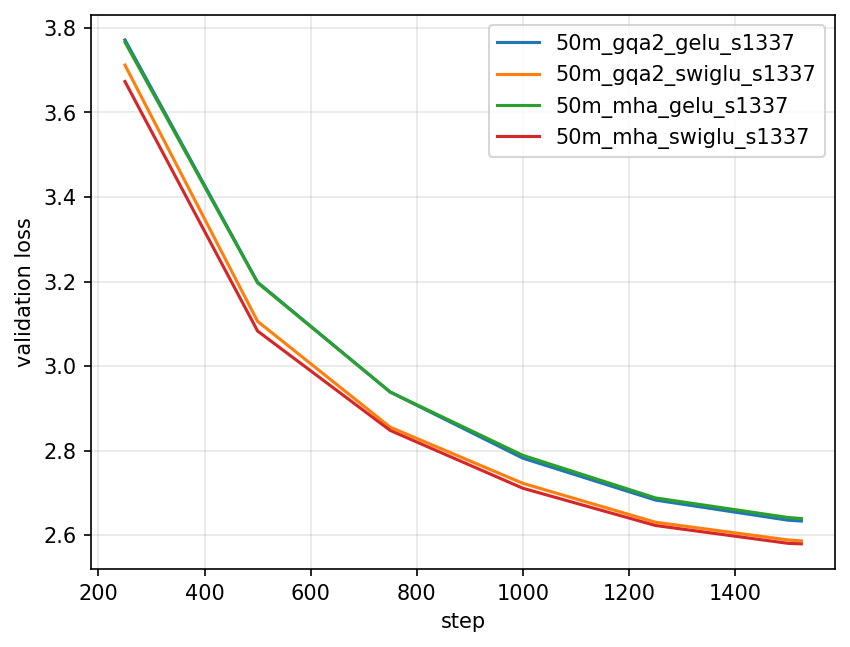

In [11]:
import glob, csv, math
print(f"{'run':32s} {'val_loss':>9s} {'ppl':>8s} {'train_time_min':>15s}")
for f in sorted(glob.glob(f"{ROOT}/runs/*/log.csv")):
    r = list(csv.DictReader(open(f)))
    if r: print(f"{f.split('/')[-2]:32s} {float(r[-1]['val_loss']):9.4f} {float(r[-1]['val_ppl']):8.2f} {float(r[-1]['elapsed_s'])/60:15.1f}")
!python plot.py --runs {ROOT}/runs --out {ROOT}/results/val_loss.png
from IPython.display import Image; Image(f"{ROOT}/results/val_loss.png")

## 8. Benchmark: KV-cache memory, latency, tokens/s, parameters

In [12]:
!python bench.py --size {SIZE} --out {ROOT}/results/bench.csv --ctxs 256,512 --batches 1,4
import pandas as pd; pd.read_csv(f"{ROOT}/results/bench.csv")

{'config': 'mha+gelu', 'params_M': 51.2, 'batch': 1, 'ctx': 256, 'kv_cache_MiB': 4.0, 'kv_formula_MiB': 4.0, 'ms_per_token': 5.05, 'tokens_per_s': 198.0, 'peak_gpu_GB': 0.11}
{'config': 'mha+gelu', 'params_M': 51.2, 'batch': 1, 'ctx': 512, 'kv_cache_MiB': 8.0, 'kv_formula_MiB': 8.0, 'ms_per_token': 3.51, 'tokens_per_s': 284.5, 'peak_gpu_GB': 0.12}
{'config': 'mha+gelu', 'params_M': 51.2, 'batch': 4, 'ctx': 256, 'kv_cache_MiB': 16.0, 'kv_formula_MiB': 16.0, 'ms_per_token': 4.06, 'tokens_per_s': 985.8, 'peak_gpu_GB': 0.14}
{'config': 'mha+gelu', 'params_M': 51.2, 'batch': 4, 'ctx': 512, 'kv_cache_MiB': 32.0, 'kv_formula_MiB': 32.0, 'ms_per_token': 3.91, 'tokens_per_s': 1023.1, 'peak_gpu_GB': 0.17}
{'config': 'gqa+gelu', 'params_M': 48.1, 'batch': 1, 'ctx': 256, 'kv_cache_MiB': 1.0, 'kv_formula_MiB': 1.0, 'ms_per_token': 4.18, 'tokens_per_s': 239.4, 'peak_gpu_GB': 0.13}
{'config': 'gqa+gelu', 'params_M': 48.1, 'batch': 1, 'ctx': 512, 'kv_cache_MiB': 2.0, 'kv_formula_MiB': 2.0, 'ms_per_tok

,config,params_M,batch,ctx,kv_cache_MiB,kv_formula_MiB,ms_per_token,tokens_per_s,peak_gpu_GB
0,mha+gelu,51.2,1,256,4.0,4.0,5.05,198.0,0.11
1,mha+gelu,51.2,1,512,8.0,8.0,3.51,284.5,0.12
2,mha+gelu,51.2,4,256,16.0,16.0,4.06,985.8,0.14
3,mha+gelu,51.2,4,512,32.0,32.0,3.91,1023.1,0.17
4,gqa+gelu,48.1,1,256,1.0,1.0,4.18,239.4,0.13
5,gqa+gelu,48.1,1,512,2.0,2.0,4.07,245.7,0.11
6,gqa+gelu,48.1,4,256,4.0,4.0,4.38,913.5,0.11
7,gqa+gelu,48.1,4,512,8.0,8.0,4.25,940.5,0.13
8,mha+swiglu,51.7,1,256,4.0,4.0,4.17,239.5,0.12
9,mha+swiglu,51.7,1,512,8.0,8.0,3.80,263.3,0.12


## 9. Generate text from a trained model

In [14]:
CKPT = f"{ROOT}/runs/{SIZE}_gqa2_swiglu_s1337/final.pt"   # folder name: <size>_<attn><kvheads>_<ffn>_s<seed>; check the runs folder
!ls {ROOT}/runs
!python generate.py --ckpt {CKPT} --prompt "The future of AI" --tokens 100

50m_gqa2_gelu_s1337    50m_mha_gelu_s1337
50m_gqa2_swiglu_s1337  50m_mha_swiglu_s1337
The future of AI not agreeing with it is “mixed”. You should be aware of the potential dangers of the word “better” in the context of the text.<|endoftext|>The key question that the author is addressing is 'What is the role of the author in writing this piece of writing?' The author provides a number of examples of success in writing this piece, such as the positive effects of the author's arguments, the impact of the author's argument on the topic, and the author's 



## Notes
- Folder names: GQA runs include the KV-head count (e.g. `50m_gqa2_swiglu_s1337`); for `30m` it is `gqa3`, for `355m` `gqa4`.
- Differences between configs of a few hundredths in loss can be noise at small token budgets; report them with that caveat.
- Parameter counts differ slightly: GQA has fewer attention parameters (not an equal-parameter comparison).